# Probabilistic alignment of evolving multigraphs and weighted networks

This repository contains the code of the paper:

Bel-Bordes, G, Lázaro, T, Guimerà R, Sales-Pardo, M. Probabilistic alignment of evolving multigraphs and weighted networks (...)

## Tutorial

This tutorial (runtime: ~4 minutes) illustrates how to use our approach for aligning multiple snapshots of a multigraph or weighted network that evolve with time. 

In here, we will go through the main functionalities of this package (i.e., align multiple snapshots, analyze results and generate unobserved snapshots).

We begin by importing all the necessary packages, including our built-in modules:

In [1]:
from aligner.networksHandling import helper as helper_networks
from aligner.poissonAlignment import helper as helper_poisson
from aligner.montecarlo import helper as helper_montecarlo
from aligner.analysis import helper as helper_analysis

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

## 1. Loading and preparing the data

We now load the data. In this example, we will consider a subset of the *C. elegans* connectomes$^{1}$.  

We will perform a group-guided alignment by considering the spatial location of the neurons (left–right, in the case of bilateral neurons). We use a reduced version of the connectomes containing only 60 neurons.  

Required inputs; to use Aligner with your own data, prepare the following inputs:
* `A`: adjacency matrices of the snapshots to be aligned (size $T \times N \times N$), where $T$ is the number of snapshots and $N$ is the number of nodes.  
* `groups`: array indicating the group membership of each node (in the same order as they appear in `A`). If one desires to do the alignment without groups, set `groups = None`.

$^{1}$ Witvliet, D. *et al.* Connectomes across development reveal principles of brain maturation. *Nature* **596**, 257–261 (2021). [https://doi.org/10.1038/s41586-021-03778-8](https://doi.org/10.1038/s41586-021-03778-8)


In [3]:
#Adjacency matrices:
labels = ["L1.1", "L1.2", "L1.3", "L1.4", "L2", "L3", "A.1", "A.2"]

A = helper_networks.load_networks(data_folder="data/celegans/", 
                                  net_ids=[l for l in range(len(labels))], file_prefix="reduced_")

T, N, N = A.shape

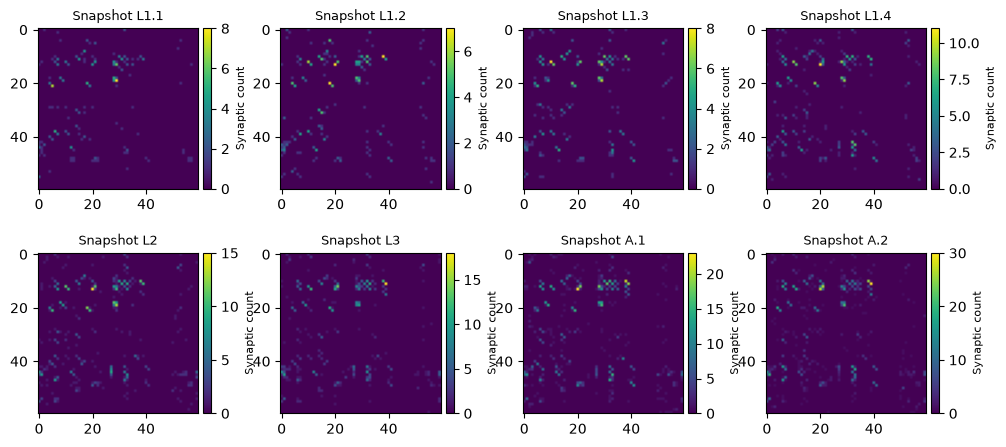

In [4]:
## Plot adjacency matrices:
fig, axes = plt.subplots(2, 4, figsize=(12, 5), gridspec_kw={'wspace':0.2, 'hspace':0.4})

for i, ax in enumerate(axes.flat):
    im = ax.imshow(A[i]); ax.set_title(f"Snapshot {labels[i]}", fontsize=9)
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    divider = make_axes_locatable(ax); cax = divider.append_axes("right", size="5%", pad=0.05)
    cbar = fig.colorbar(im, cax=cax); cbar.set_label("Synaptic count", fontsize=8)

plt.show()

In [5]:
#Groups:
neuron_metadata = pd.read_csv("data/celegans/reduced_neuron_metadata.csv", index_col=0) 
groups = np.array(neuron_metadata["location"])
print(groups)

['Left' 'Right' 'Left' 'Right' 'Left' 'Right' 'Left' 'Right' 'Left'
 'Right' 'Left' 'Right' 'Left' 'Right' 'Left' 'Right' 'Left' 'Right'
 'Left' 'Right' 'Left' 'Right' 'Other' 'Left' 'Right' 'Left' 'Right'
 'Right' 'Left' 'Right' 'Left' 'Right' 'Left' 'Right' 'Left' 'Right'
 'Left' 'Right' 'Left' 'Right' 'Left' 'Right' 'Left' 'Right' 'Left'
 'Right' 'Left' 'Right' 'Left' 'Right' 'Left' 'Right' 'Left' 'Right'
 'Left' 'Right' 'Left' 'Right' 'Left' 'Other']


## 2. Sampling alignments

Once the data are loaded, we proceed to run Monte Carlo (MC) simulations to sample the space of alignments.  
In practice, we sample pairs of blueprint–node mappings, which are formally defined as permutations for each snapshot.

Here, we run one MC simulation with **parallel tempering** — meaning that several replicas of the system are simulated at different temperatures (recall that $\beta = 1 / \text{Temperature}$).  
In a full analysis, we typically perform five independent runs (see `1_alignment_networks.ipynb` for reference).  
Since we are working with connectomes and aim to preserve the left–right symmetry, we use a **group-guided alignment**.

We must define the following parameters:

* `MCsteps`: number of Monte Carlo steps.  
* `start_sampling`: MC step from which to start storing alignments at temperature 1 (i.e., those used in the ensemble).  
* `freq_sampling`: number of steps between two consecutive samples of the ensemble.  
* `betas`: inverse temperatures corresponding to each parallel tempering replica.  
* `initial_P`: initial permutation (node mapping). We initialize it by ordering nodes according to their strength within each snapshot.  

In [6]:
#Parameters of the Monte Carlo:
MCsteps = 3000
start_sampling = 1500
freq_sampling = 1

## Parallel tempering:
betas = np.array([1.005**n for n in range(-12,1)])

In [7]:
#Initial permutation of the snapshots:
initial_P = helper_montecarlo.initial_permutation_groups(A, groups) #nodes are ordered by strength

Groups: ['Left' 'Other' 'Right']
Group boundary array: [ 0 29 31 60]


In [8]:
Esweeps_r, samples, groundState, MCacceptance_rate = helper_montecarlo.sampling_poisson_groups(A=A, 
    P=initial_P, betas=betas, S=MCsteps, sampleFrom=start_sampling, sampleFreq=freq_sampling, 
    groups=groups, filesave=None)

Sweeps: 100%|██████████████████████████████| 3000/3000 [03:35<00:00, 13.92it/s]

Replica with minimum energy: 3


In case one desires to run the MC **without group constraints**, the following changes must be made:

* Instead of `helper_montecarlo.initial_permutation(..., groups=groups)`, use `helper_montecarlo.initial_permutation(...)` — same arguments but without the `groups` parameter.  
* Instead of `helper_montecarlo.sampling_poisson(..., groups=groups)`, use `helper_montecarlo.sampling_poisson(...)` — same arguments but without the `groups` parameter.



## 3. Analyzing the alignment results

After sampling alignments with the MC procedure, we analyze the results.  
Specifically, we are interested in the **mapping of nodes across snapshots**.

In this section, we will:

1. Visualize the MC process by plotting the **alignment energy** over the MC steps and comparing it to the energy of the **ground-truth alignment**.  
2. Compare the **inferred node mappings** (obtained from the ensemble of sampled permutations) to the **ground-truth mappings**.

Ground Truth Energy = -8573.74925771809


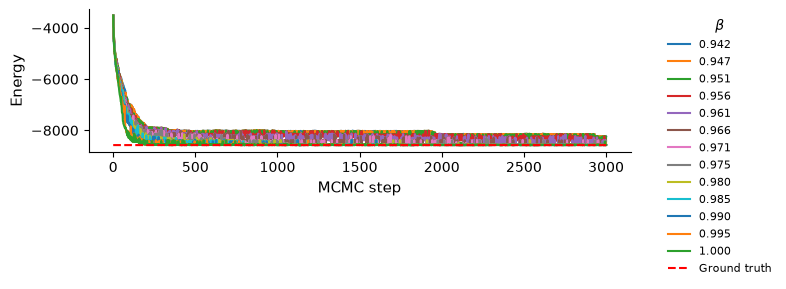

In [9]:
#Ground truth energy:
gtP = np.array([[n for n in range (N)] for t in range(T)]) #GT permutation is the same permutation for each snapshot (bc nodes are originally ordered in the same way)
Egt = helper_poisson.calculateEnergy_total(A, gtP, helper_poisson.get_Salpha(A), N, T)
print(f"Ground Truth Energy = {Egt}")

fig, ax = plt.subplots(figsize=(8, 2.5))
for b, beta in enumerate(betas):
    ax.plot(Esweeps_r[b], label=f"{beta:.3f}")
ax.plot([Egt] * len(Esweeps_r[b]), 'r--', label="Ground truth")
ax.set_xlabel("MCMC step", fontsize=11); ax.set_ylabel("Energy", fontsize=11)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.legend(title=r"$\beta$", fontsize=8, frameon=False, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Groups: ['Left' 'Other' 'Right']
Group boundary array: [ 0 29 31 60]


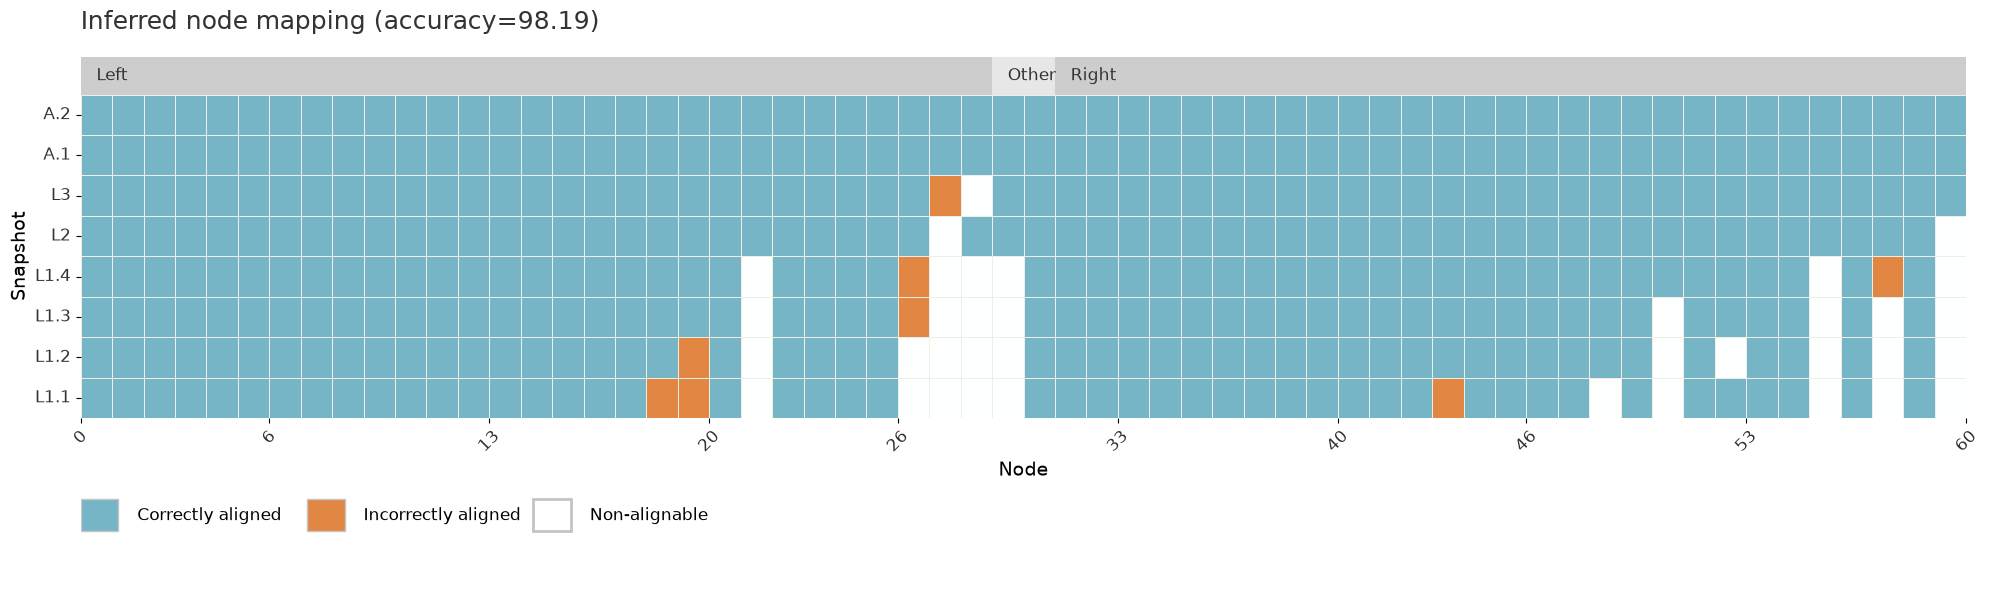

In [10]:
#Inferred node mapping:
ensemble = samples
ensemble_node_mapping = helper_analysis.infer_node_mapping(ensemble)
ensemble_node_mapping = helper_analysis.mark_empty_nodes(ensemble_node_mapping, A)
ensemble_node_mapping = helper_analysis.order_node_mapping(ensemble_node_mapping, A, groups) #to sort nodes by desc strngth in the densest snapshot (in this case, A.2)

accuracy = helper_analysis.compute_accuracy(ensemble_node_mapping) #disregarding non-alignable nodes
helper_analysis.show_alignment(ensemble_node_mapping, N, T, True, True, labels, 
                               f"Inferred node mapping (accuracy={100*accuracy:.2f})", groups); #groups=None if we have no groups

## 3. Generating unobserved snapshots

One key contribution of our approach, besides the alignment, is the ability to accurately generate unobserved snapshots. For this, we first infer the blueprint from the ensemble of alignments.

Since the developmental parameter ($\alpha^t$) shows a linear relationship with the original timestep, as shown in the figure below, we can generate the connectomes at two intermediate states between L3 and A.1 with $\alpha^t \approx 0.65$ and $0.75$, for example.

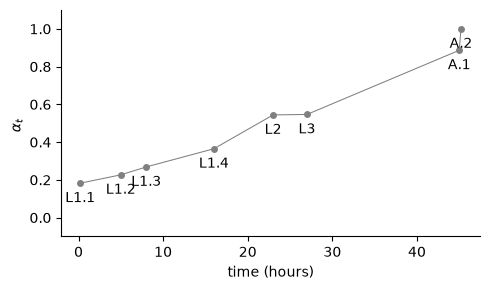

In [11]:
#See relationship between alpha and real time step:
alpha_values = helper_poisson.get_alpha(A, helper_poisson.get_ST(A))
time_values = [ 0.2,  5. ,  8. , 16. , 23. , 27. , 45. , 45.2] #from Wivliet paper (in hours)

plt.figure(figsize=(5, 3)); plt.plot(time_values, alpha_values, color='grey', lw=0.75); plt.scatter(time_values, alpha_values, color='grey', s=25, linewidths=0)
plt.ylim([-0.1, 1.1]); plt.xlabel("time (hours)"); plt.ylabel(r"$\alpha_t$ "); 
for t, alpha, label in zip(time_values, alpha_values, labels):
    plt.text(t, alpha - 0.1, str(label), ha='center', fontsize=10)
ax = plt.gca(); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

In [12]:
#Infer blueprint:
inferred_blueprint = helper_analysis.infer_blueprint(A, ensemble)

In [13]:
#Select alphas of the new connectomes:
alpha_generated_connectome = [0.65, 0.75]

In [14]:
#Generate:
generated_connectomes = helper_poisson.synthesize_networks(inferred_blueprint, alpha_generated_connectome)

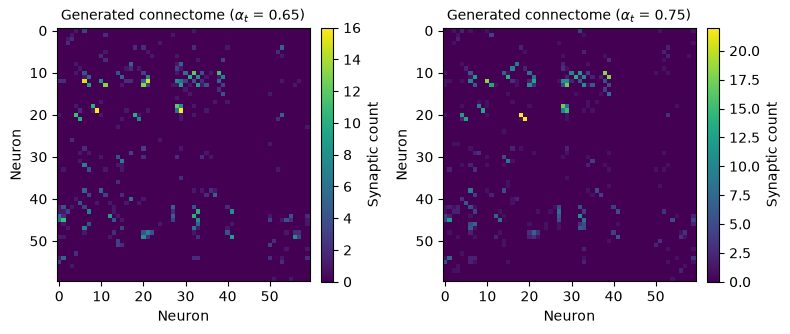

In [15]:
#See results:
M = len(generated_connectomes)
fig, axes = plt.subplots(1, M, figsize=(4*M, 4))  
for i, (ax, predA) in enumerate(zip(axes, generated_connectomes)):
    im = ax.imshow(predA, cmap='viridis')
    ax.set_title(fr"Generated connectome ($\alpha_t$ = {alpha_generated_connectome[i]:.2f})", fontsize=10)
    ax.set_xlabel("Neuron")
    ax.set_ylabel("Neuron")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Synaptic count")

plt.tight_layout()
plt.show()

_____________
For further analysis (for example, for comparing inferred model rates with real synaptic counts, see notebook `2_analysis_alignment.ipynb`).